# Stage 2 of 3 - Exploratory Data Analysis: Indian Railways

*Part of the SWYNEX Final Data Science Project: prepare -> explore -> model -> conclude.*

**Input:** the cleaned tables produced in Stage 1: 5,193 trains and 8,975 stations.

**Goal:** use statistics and visualisations to find insights that could change how
a model is built or how a decision is made. Every insight below is backed by a test
or an effect size, and ends with a "so what" for modelling or decisions.

**Guiding question:** *What drives how fast an Indian train runs, and what should a
model of train speed (or a planner) pay attention to?*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import os
# Run from the project root whether launched from the root, scripts/ or notebooks/
if Path.cwd().name in ("scripts", "notebooks"):
    os.chdir(Path.cwd().parent)

FIG = Path("reports/figures/eda")
REP = Path("reports/eda")
REP.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#4C72B0", "#C44E52", "#55A868", "#DD8452", "#8172B2", "#8C8C8C"


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()

## 1. Load the prepared data
Station codes are text identifiers (e.g. `NAN`), so the CSVs are read with
`keep_default_na=False` to stop pandas turning codes into nulls (lesson from Stage 1).

In [2]:
RD = dict(keep_default_na=False, na_values=[""])
trains = pd.read_csv("data/processed/trains_clean.csv",
                     dtype={"train_id": str, "train_no": str, "return_train_no": str}, **RD)
stations = pd.read_csv("data/processed/stations_clean.csv", **RD)
print("Trains  :", trains.shape)
print("Stations:", stations.shape)

# Speed analysis excludes the 3 rows flagged as implausible in Stage 1 (e.g. 540 km/h).
speed = trains[~trains["speed_suspect"] & trains["avg_speed_kmph"].notna()].copy()
print(f"Speed analysis uses {len(speed):,} trains "
      f"({int(trains['speed_suspect'].sum())} suspect rows excluded, "
      f"{int(trains['avg_speed_kmph'].isna().sum())} with no distance)")

Trains  : (5193, 40)
Stations: (8975, 9)
Speed analysis uses 5,163 trains (3 suspect rows excluded, 27 with no distance)


## 2. Overview: summary statistics

In [3]:
num_cols = ["distance_km", "duration_min", "avg_speed_kmph", "n_classes", "route_points"]
summary = speed[num_cols].describe().T
summary["skew"] = speed[num_cols].skew()
summary["median"] = speed[num_cols].median()
summary = summary.round(2)
summary.to_csv(REP / "summary_statistics.csv")
print(summary[["count", "mean", "median", "std", "min", "max", "skew"]])

print("\nCategorical overview")
print("  Train types :", trains["train_type"].nunique(), "| zones:", trains["zone"].nunique())
print("  Overnight   :", f"{trains['is_overnight'].mean():.1%}")
print("  Slip coaches:", f"{trains['is_slip_coach'].mean():.1%}")
print("  Has a return train:", f"{trains['return_train_no'].notna().mean():.1%}")

                 count    mean  median     std   min     max  skew
distance_km     5163.0  547.81   229.0  697.64   2.0  4279.0  1.85
duration_min    5163.0  677.53   365.0  760.56  10.0  5130.0  1.81
avg_speed_kmph  5163.0   41.66    40.3   12.84   8.6    89.5  0.37
n_classes       5163.0    1.13     0.0    1.41   0.0     5.0  0.78
route_points    5163.0   79.85    34.0  100.21   1.0   684.0  1.99

Categorical overview
  Train types : 16 | zones: 18
  Overnight   : 37.4%
  Slip coaches: 1.3%
  Has a return train: 88.5%


## 3. Insight 1 - Distance is heavily skewed: log-transform it
Half of all trains run under ~230 km, but a long tail runs up to 4,279 km.

Mean 548 km vs median 228 km
Skewness raw = 1.86  ->  after log = -0.12
IQR outliers: 555 trains (10.7%) - real long-distance trains, not errors


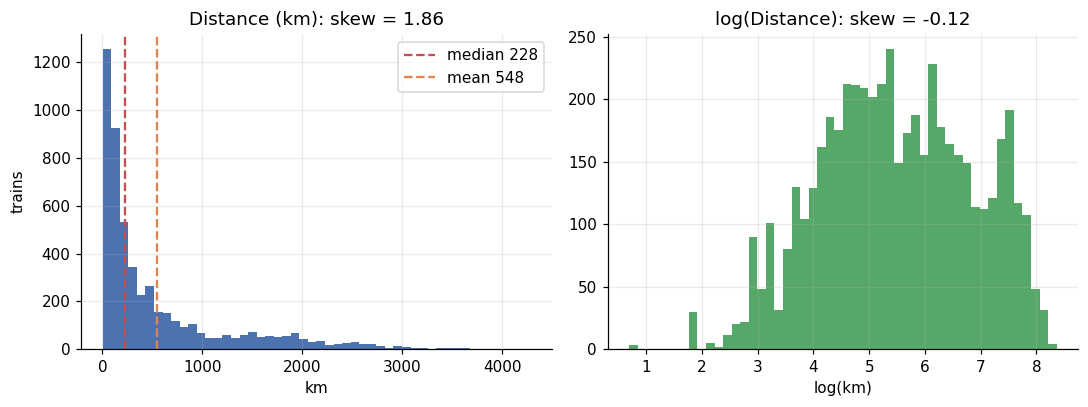

In [4]:
dist = trains["distance_km"].dropna()
skew_raw, skew_log = dist.skew(), np.log(dist).skew()
q1, q3 = dist.quantile([0.25, 0.75])
n_out = int((dist > q3 + 1.5 * (q3 - q1)).sum())
print(f"Mean {dist.mean():.0f} km vs median {dist.median():.0f} km")
print(f"Skewness raw = {skew_raw:.2f}  ->  after log = {skew_log:.2f}")
print(f"IQR outliers: {n_out} trains ({n_out/len(dist):.1%}) - real long-distance trains, not errors")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].hist(dist, bins=50, color=BLUE)
ax[0].axvline(dist.median(), color=RED, ls="--", label=f"median {dist.median():.0f}")
ax[0].axvline(dist.mean(), color=ORANGE, ls="--", label=f"mean {dist.mean():.0f}")
ax[0].set(title=f"Distance (km): skew = {skew_raw:.2f}", xlabel="km", ylabel="trains")
ax[0].legend()
ax[1].hist(np.log(dist), bins=50, color=GREEN)
ax[1].set(title=f"log(Distance): skew = {skew_log:.2f}", xlabel="log(km)")
save("01_distance_skew.png")

**So what:** use `log(distance_km)` as a model feature. The 555 "outliers" are genuine
long-haul trains, so they should be **kept**, not removed.

## 4. Insight 2 - Distance, duration and route length are almost the same variable
And `avg_speed = distance / duration`, so using duration to predict speed is **target leakage**.

                distance_km  duration_min  route_points  route_km_geo  \
distance_km            1.00          0.98          0.95          0.99   
duration_min           0.98          1.00          0.92          0.97   
route_points           0.95          0.92          1.00          0.96   
route_km_geo           0.99          0.97          0.96          1.00   
avg_speed_kmph         0.70          0.55          0.68          0.70   
n_classes              0.80          0.75          0.80          0.79   
departure_min          0.17          0.16          0.17          0.18   

                avg_speed_kmph  n_classes  departure_min  
distance_km               0.70       0.80           0.17  
duration_min              0.55       0.75           0.16  
route_points              0.68       0.80           0.17  
route_km_geo              0.70       0.79           0.18  
avg_speed_kmph            1.00       0.70           0.17  
n_classes                 0.70       1.00           0.31  
de

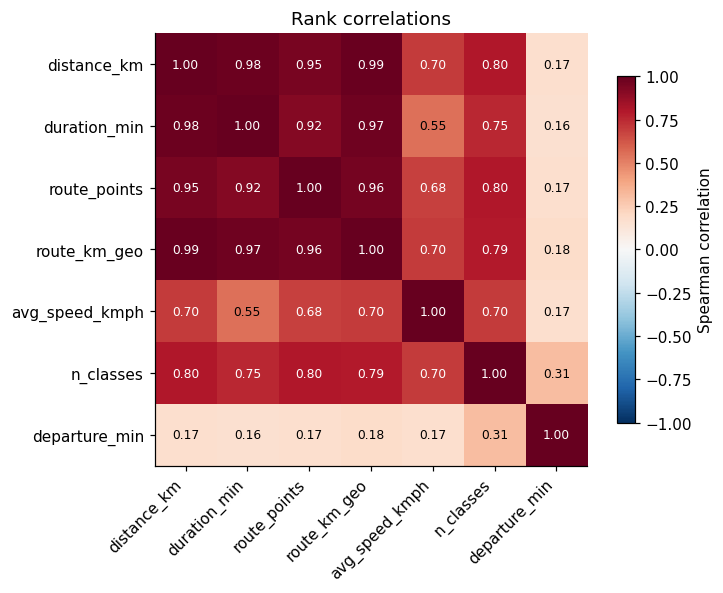

In [5]:
corr_cols = ["distance_km", "duration_min", "route_points", "route_km_geo",
             "avg_speed_kmph", "n_classes", "departure_min"]
corr = speed[corr_cols].corr(method="spearman").round(2)
print(corr)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black", fontsize=8)
ax.grid(False)
plt.colorbar(im, shrink=0.8, label="Spearman correlation")
ax.set_title("Rank correlations")
save("02_correlation_heatmap.png")

**So what:** `distance_km`, `duration_min`, `route_points` and `route_km_geo` are
near-duplicates (Spearman 0.92-0.99). Keep **one** (distance). For a speed model, never
include duration: it would reconstruct the target.

## 5. Insight 3 - Train type drives speed far more than zone does
I compare how much of the variation in speed each feature explains (R-squared from
ordinary least squares with dummy variables).

zone only                 0.125
log(distance) only        0.467
train type only           0.681
distance + zone           0.512
distance + type           0.714
distance + type + zone    0.745
dtype: float64

Adding zone to distance+type improves R2 by only +0.031


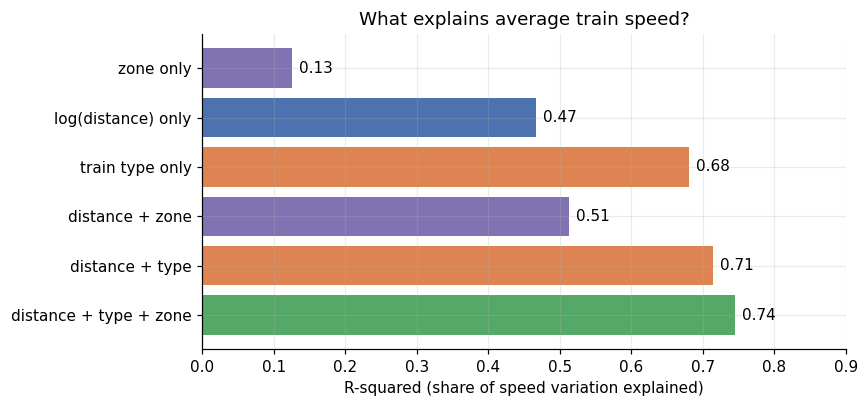

In [6]:
y = speed["avg_speed_kmph"].to_numpy(float)
log_d = np.log(speed["distance_km"].to_numpy(float))
T = pd.get_dummies(speed["train_type"].astype(str), drop_first=True).to_numpy(float)
Z = pd.get_dummies(speed["zone"].astype(str), drop_first=True).to_numpy(float)


def r2(*blocks):
    X = np.column_stack([np.ones(len(y))] + list(blocks))
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return 1 - (y - X @ beta).var() / y.var()


ladder = pd.Series({
    "zone only": r2(Z),
    "log(distance) only": r2(log_d),
    "train type only": r2(T),
    "distance + zone": r2(log_d, Z),
    "distance + type": r2(log_d, T),
    "distance + type + zone": r2(log_d, T, Z),
})
print(ladder.round(3))
print(f"\nAdding zone to distance+type improves R2 by only {ladder['distance + type + zone'] - ladder['distance + type']:+.3f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [PURPLE, BLUE, ORANGE, PURPLE, ORANGE, GREEN]
ax.barh(ladder.index, ladder.values, color=colors)
for i, v in enumerate(ladder.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set(xlabel="R-squared (share of speed variation explained)", xlim=(0, 0.9),
       title="What explains average train speed?")
ax.invert_yaxis()
save("03_r2_ladder.png")

**So what:** train type alone explains ~68% of speed variation versus ~13% for zone.
For a speed model, train type is the first feature to include; zone is a minor refinement.

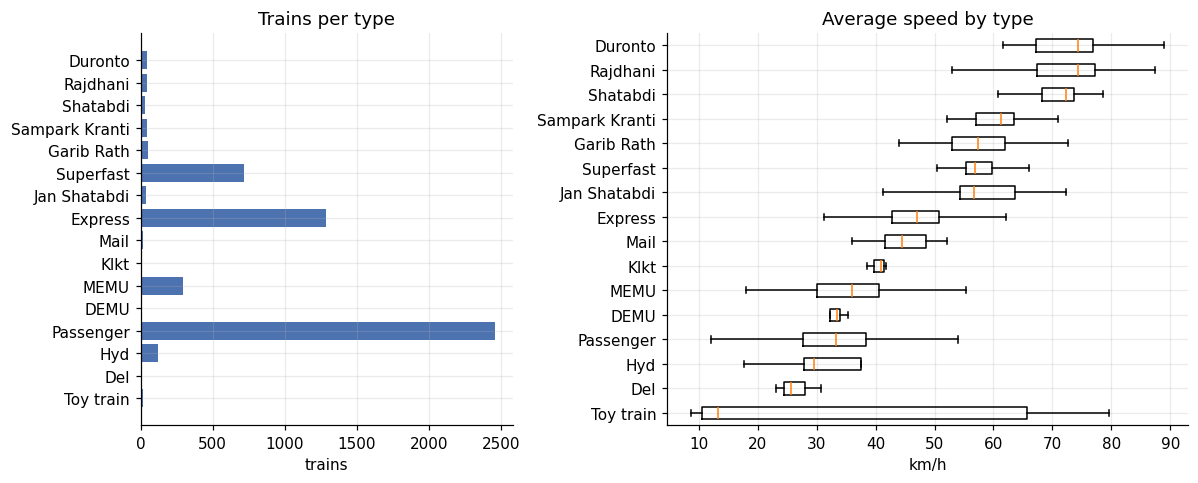

Types with fewer than 15 trains: ['Toy train', 'Del', 'DEMU (diesel multiple unit)', 'Klkt']


In [7]:
order = speed.groupby("train_type")["avg_speed_kmph"].median().sort_values().index
counts = trains["train_type"].value_counts().reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].barh([str(t).split(" (")[0] for t in order], counts.values, color=BLUE)
ax[0].set(title="Trains per type", xlabel="trains")
ax[1].boxplot([speed.loc[speed.train_type == t, "avg_speed_kmph"] for t in order], vert=False,
              tick_labels=[str(t).split(" (")[0] for t in order], showfliers=False)
ax[1].set(title="Average speed by type", xlabel="km/h")
save("04_type_counts_and_speed.png")
print("Types with fewer than 15 trains:", list(counts[counts < 15].index))

Note the **class imbalance**: Passenger and Express make up 72% of trains, while
4 types have fewer than 15 trains each. Rare types should be grouped before modelling.

## 6. Insight 4 - Speed rises with distance, but saturates
Short hops are slow (many stops per km); beyond ~1,000 km speed barely improves.

           count  median  share_of_trains
dist_bin                                 
<100        1431    31.7            0.277
100-300     1449    36.4            0.281
300-600      822    45.1            0.159
600-1000     518    50.7            0.100
1000-1500    298    52.5            0.058
>1500        645    55.1            0.125

Spearman rho (distance vs speed) = 0.70, p = 0.0e+00
Trains under 300 km: 55.6%


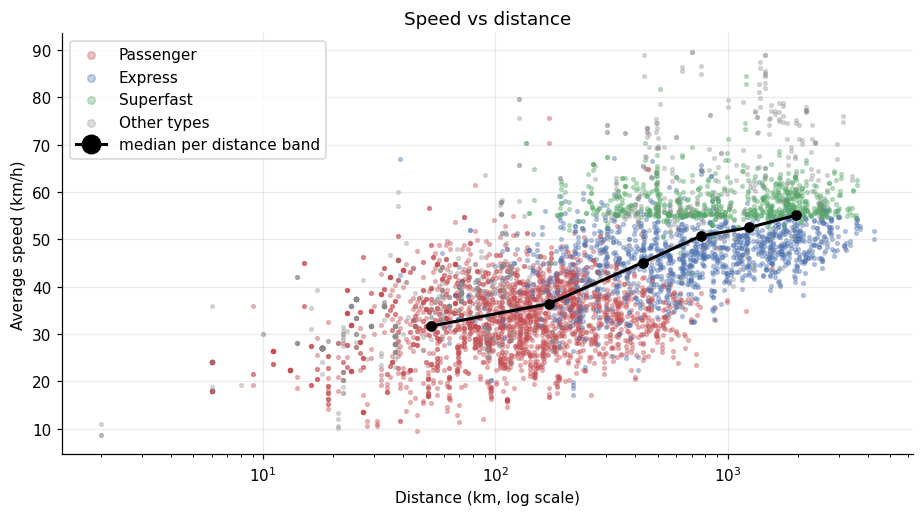

In [8]:
speed["dist_bin"] = pd.cut(speed["distance_km"], [0, 100, 300, 600, 1000, 1500, 4500],
                           labels=["<100", "100-300", "300-600", "600-1000", "1000-1500", ">1500"])
by_bin = speed.groupby("dist_bin", observed=True)["avg_speed_kmph"].agg(["count", "median"]).round(1)
by_bin["share_of_trains"] = (by_bin["count"] / by_bin["count"].sum()).round(3)
print(by_bin)
rho, p = stats.spearmanr(speed["distance_km"], speed["avg_speed_kmph"])
print(f"\nSpearman rho (distance vs speed) = {rho:.2f}, p = {p:.1e}")
short_share = (speed["distance_km"] < 300).mean()
print(f"Trains under 300 km: {short_share:.1%}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
major = speed["train_type"].isin(["Passenger", "Express", "Superfast"])
for name, col in [("Passenger", RED), ("Express", BLUE), ("Superfast", GREEN)]:
    s_ = speed[speed.train_type == name]
    ax.scatter(s_["distance_km"], s_["avg_speed_kmph"], s=6, alpha=0.35, color=col, label=name)
ax.scatter(speed.loc[~major, "distance_km"], speed.loc[~major, "avg_speed_kmph"],
           s=6, alpha=0.3, color=GREY, label="Other types")
mids = speed.groupby("dist_bin", observed=True)["distance_km"].median()
ax.plot(mids.values, by_bin["median"].values, "k-o", lw=2, label="median per distance band")
ax.set(xscale="log", xlabel="Distance (km, log scale)", ylabel="Average speed (km/h)",
       title="Speed vs distance")
ax.legend(markerscale=2)
save("05_speed_vs_distance.png")

**So what:** the relationship is non-linear (a plain straight line would fit badly).
Use `log(distance)` or distance bands, or a tree-based model. Also, **56% of trains run under
300 km and are the slowest**, so improvements to short local services touch the most trains.

## 7. Insight 5 - Zone gaps look big, but mostly reflect train mix
Raw zone medians range from ~32 to ~51 km/h. Do zones differ *within the same train type*?

Raw zone medians (zones with n>=100):
zone      ECR    NER   SECR    SCR    NCR     NR    NFR     WR     SR    SWR  \
count   252.0  387.0  118.0  437.0  135.0  625.0  217.0  470.0  606.0  227.0   
median   31.6   33.1   35.8   37.6   37.9   39.4   41.7   42.0   42.0   42.9   

zone      NWR     ER     CR   ECoR    SER  
count   232.0  364.0  359.0  120.0  248.0  
median   43.6   43.7   48.0   50.0   50.8  

Within one train type:
train_type  zones_compared  min_median  max_median  spread kruskal_p
 Passenger              16        25.7       38.00   12.30   2.9e-53
   Express              13        43.2       50.95    7.75   7.7e-37

Raw spread across zones: 19.1 km/h


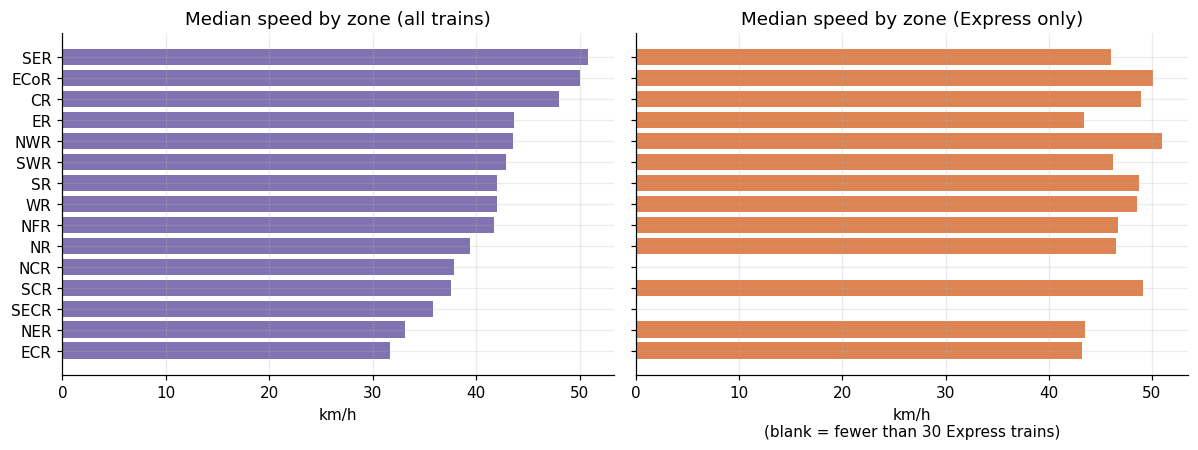

In [9]:
zone_med = speed[speed.zone != "Unknown"].groupby("zone")["avg_speed_kmph"].agg(["count", "median"])
zone_med = zone_med[zone_med["count"] >= 100].sort_values("median")
print("Raw zone medians (zones with n>=100):")
print(zone_med.round(1).T)

rows = []
for ty in ["Passenger", "Express"]:
    sub = speed[(speed.train_type == ty) & (speed.zone != "Unknown")]
    grp = [g["avg_speed_kmph"].to_numpy() for _, g in sub.groupby("zone") if len(g) >= 30]
    h, pval = stats.kruskal(*grp)
    meds = sub.groupby("zone")["avg_speed_kmph"].agg(["count", "median"]).query("count >= 30")["median"]
    rows.append({"train_type": ty, "zones_compared": len(grp), "min_median": meds.min(),
                 "max_median": meds.max(), "spread": meds.max() - meds.min(), "kruskal_p": pval})
within = pd.DataFrame(rows)
print("\nWithin one train type:")
print(within.assign(kruskal_p=within["kruskal_p"].map("{:.1e}".format)).round(2).to_string(index=False))
print(f"\nRaw spread across zones: {zone_med['median'].max() - zone_med['median'].min():.1f} km/h")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
ax[0].barh(zone_med.index, zone_med["median"], color=PURPLE)
ax[0].set(title="Median speed by zone (all trains)", xlabel="km/h")
exp = speed[(speed.train_type == "Express") & (speed.zone != "Unknown")]
em = exp.groupby("zone")["avg_speed_kmph"].agg(["count", "median"]).query("count >= 30")["median"]
em = em.reindex(zone_med.index).dropna()
ax[1].barh(em.index, em.values, color=ORANGE)
ax[1].set(title="Median speed by zone (Express only)", xlabel="km/h\n(blank = fewer than 30 Express trains)")
save("06_zone_effect.png")

**So what:** zones still differ significantly inside a train type (Kruskal-Wallis p < 1e-35),
so zone carries *some* signal, but the gap shrinks once type is held fixed (19.1 km/h overall, 12.3 within Passenger, 7.8 within Express). In a
model, include zone **alongside** type; do not read raw zone averages as zone "performance".

## 8. Insight 6 - Missing zone is not random
In Stage 1, 275 trains had no recoverable zone. What kind of trains are they?

                               unknown_zone  known_zone
train_type                                             
Passenger                             0.582       0.467
MEMU (electric multiple unit)         0.364       0.040
Express                               0.055       0.259
DEMU (diesel multiple unit)           0.000       0.001
Garib Rath                            0.000       0.011

Median distance: unknown-zone 56 km vs known-zone 256 km
Mann-Whitney U on distance: p = 5.8e-74


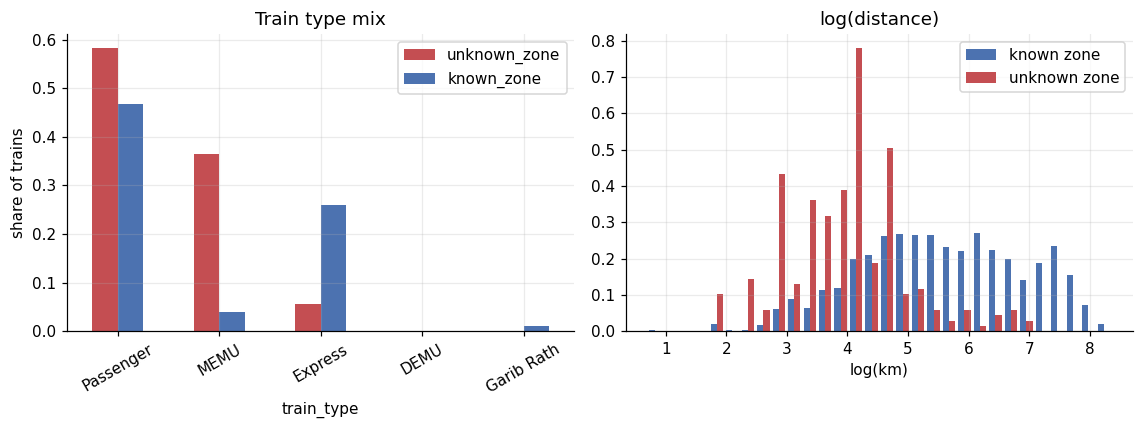

In [10]:
unk = trains[trains.zone == "Unknown"]
kn = trains[trains.zone != "Unknown"]
mix = pd.DataFrame({
    "unknown_zone": unk["train_type"].value_counts(normalize=True),
    "known_zone": kn["train_type"].value_counts(normalize=True),
}).fillna(0).sort_values("unknown_zone", ascending=False).head(5).round(3)
print(mix)
print(f"\nMedian distance: unknown-zone {unk['distance_km'].median():.0f} km vs known-zone {kn['distance_km'].median():.0f} km")
u, pu = stats.mannwhitneyu(unk["distance_km"].dropna(), kn["distance_km"].dropna())
print(f"Mann-Whitney U on distance: p = {pu:.1e}")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
mix.rename(index=lambda s: str(s).split(" (")[0]).plot.bar(ax=ax[0], color=[RED, BLUE], rot=30)
ax[0].set(title="Train type mix", ylabel="share of trains")
ax[1].hist([np.log(kn["distance_km"].dropna()), np.log(unk["distance_km"].dropna())], bins=30,
           color=[BLUE, RED], label=["known zone", "unknown zone"], density=True)
ax[1].set(title="log(distance)", xlabel="log(km)")
ax[1].legend()
save("07_unknown_zone.png")

**So what:** unknown-zone trains are overwhelmingly short **Passenger and MEMU** locals
(about 95% of them vs ~51% elsewhere; median 56 km vs 256 km). The missingness is
**informative**: dropping these rows would bias the data toward long-distance trains, and
filling them with the most common zone would be wrong. Keep `Unknown` as its own category.

## 9. Insight 7 - Distance sets the "service regime"
Overnight running and air-conditioned classes switch on sharply between 300 and 1,000 km.

          trains overnight  has_ac  mean_classes
dist_bin                                        
<100        1432  0.013966    0.01          0.07
100-300     1450  0.077931    0.04          0.26
300-600      823  0.467801    0.37          1.43
600-1000     518  0.930502    0.86          2.75
>1000        943   0.99894    0.97          2.90

Share of trains with no class listed: Passenger 92%, Express 12%


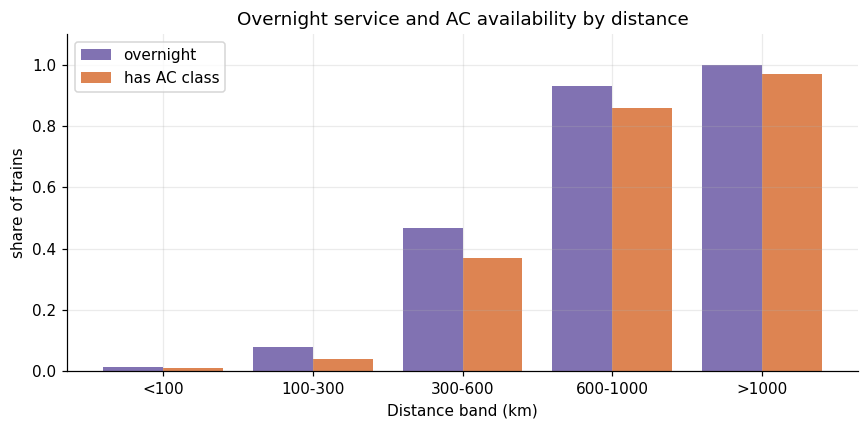

In [11]:
trains["dist_bin"] = pd.cut(trains["distance_km"], [0, 100, 300, 600, 1000, 4500],
                            labels=["<100", "100-300", "300-600", "600-1000", ">1000"])
trains["has_ac"] = trains[["first_ac", "second_ac", "third_ac"]].any(axis=1)
regime = trains.groupby("dist_bin", observed=True).agg(
    trains=("train_id", "count"), overnight=("is_overnight", "mean"),
    has_ac=("has_ac", "mean"), mean_classes=("n_classes", "mean")).round(2)
print(regime)
no_class = trains.groupby("train_type")["n_classes"].apply(lambda s: (s == 0).mean())
print(f"\nShare of trains with no class listed: Passenger {no_class['Passenger']:.0%}, Express {no_class['Express']:.0%}")

x = np.arange(len(regime))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, regime["overnight"], 0.4, label="overnight", color=PURPLE)
ax.bar(x + 0.2, regime["has_ac"], 0.4, label="has AC class", color=ORANGE)
ax.set_xticks(x, regime.index)
ax.set(xlabel="Distance band (km)", ylabel="share of trains", ylim=(0, 1.1),
       title="Overnight service and AC availability by distance")
ax.legend()
save("08_distance_regimes.png")

**So what:** use **distance bands** (break points near 300 and 600 km) as features, or
let a tree model find them. `n_classes` is largely a proxy for type + distance
(Spearman ~ 0.8 with distance), so it adds little new information to a speed model.

## 10. Insight 8 - Return-train pairs are a built-in consistency check
88.5% of trains list a return train. A train and its return should cover the same distance.

Pairs with both distances known: 4,528
Distance agrees within 1%: 95.5%
Pairs disagreeing by more than 10%: 84


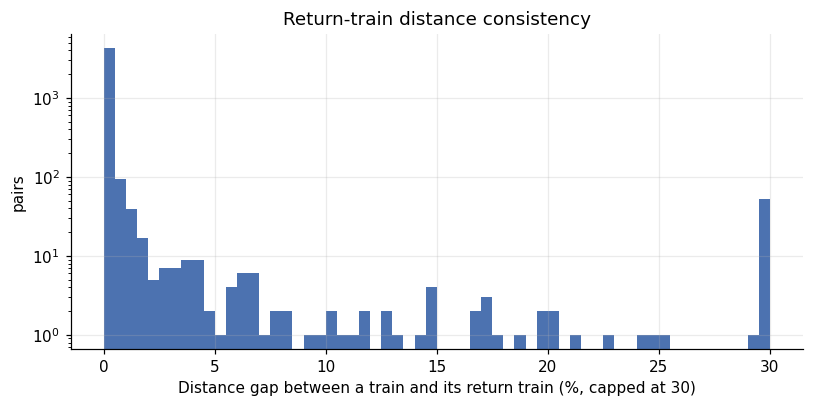

In [12]:
pairs = trains.dropna(subset=["return_train_no"]).merge(
    trains[["train_id", "distance_km", "duration_min"]].rename(
        columns={"train_id": "return_train_no", "distance_km": "ret_dist", "duration_min": "ret_dur"}),
    on="return_train_no")
pairs = pairs.dropna(subset=["distance_km", "ret_dist"])
pairs["dist_gap"] = (pairs["distance_km"] - pairs["ret_dist"]).abs() / pairs["distance_km"]
within1 = (pairs["dist_gap"] <= 0.01).mean()
big = pairs[pairs["dist_gap"] > 0.10]
print(f"Pairs with both distances known: {len(pairs):,}")
print(f"Distance agrees within 1%: {within1:.1%}")
print(f"Pairs disagreeing by more than 10%: {len(big)}")
big.sort_values("dist_gap", ascending=False)[
    ["train_id", "name", "distance_km", "return_train_no", "ret_dist", "dist_gap"]
].head(100).round(3).to_csv(REP / "return_pair_distance_mismatches.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.hist(pairs["dist_gap"].clip(upper=0.3) * 100, bins=60, color=BLUE)
ax.set(xlabel="Distance gap between a train and its return train (%, capped at 30)",
       ylabel="pairs", title="Return-train distance consistency", yscale="log")
save("09_return_pairs.png")

**So what:** 95.5% of pairs agree within 1%, so a pair mismatch above 10% (84 pairs) is a
strong, free **anomaly signal**: a candidate list for manual review, saved in
`reports/return_pair_distance_mismatches.csv`. It can also validate any future imputation.

## 11. Context: when trains leave, and where stations are
Departures show two daily peaks (morning 5-7h and evening 17-18h). The station map is built
only from coordinates; no map library is needed.

Share of departures in the 5-7h and 17-18h peaks: 34.4%


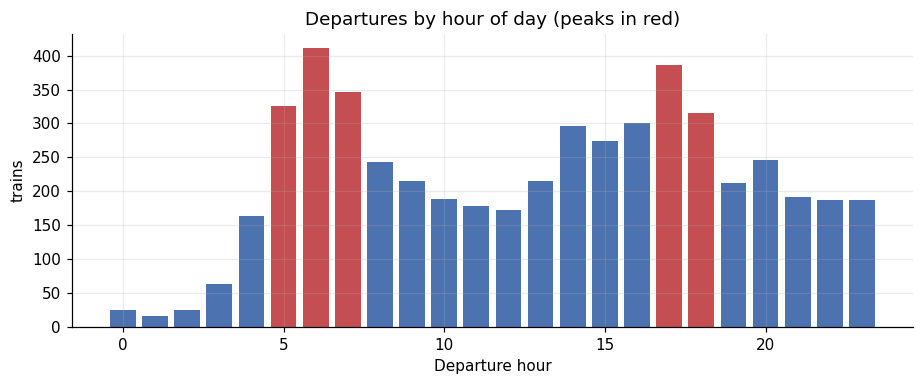

In [13]:
hours = (trains["departure_min"] // 60).value_counts().sort_index()
peak_share = hours.loc[[5, 6, 7, 17, 18]].sum() / hours.sum()
print(f"Share of departures in the 5-7h and 17-18h peaks: {peak_share:.1%}")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(hours.index, hours.values, color=[RED if h in (5, 6, 7, 17, 18) else BLUE for h in hours.index])
ax.set(xlabel="Departure hour", ylabel="trains", title="Departures by hour of day (peaks in red)")
save("10_departure_hours.png")

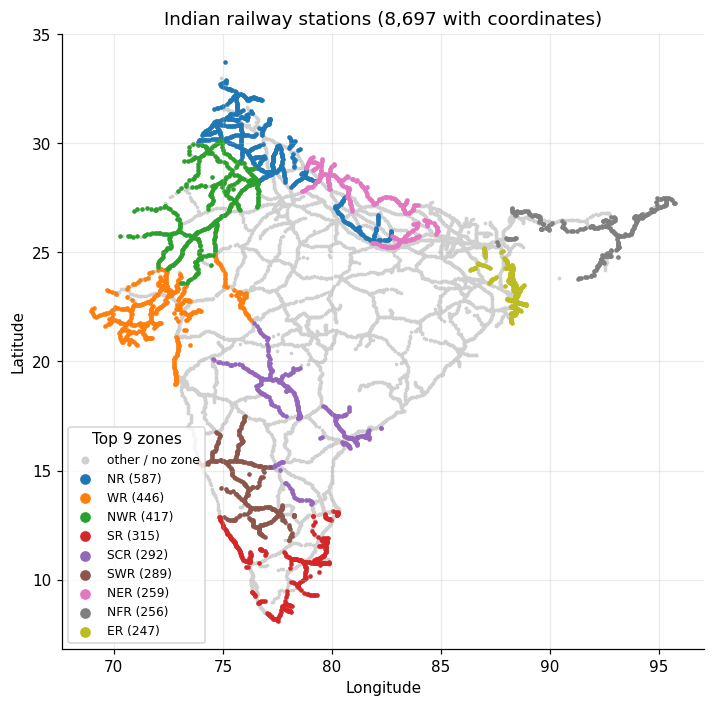


Stations by state (top 8; state known for only about half of stations):
state
Uttar Pradesh     529
Rajasthan         451
Gujarat           422
Maharashtra       378
West Bengal       345
Madhya Pradesh    316
Karnataka         301
Tamil Nadu        253
Name: count, dtype: int64
State known for 49.0% of stations -> geographic findings are limited.


In [14]:
geo = stations.dropna(subset=["lat", "lon"])
zones_top = geo["zone"].value_counts().head(9).index
fig, ax = plt.subplots(figsize=(6.6, 7.2))
ax.scatter(geo["lon"], geo["lat"], s=2, color="#D0D0D0", label="other / no zone")
cmap = plt.get_cmap("tab10")
for i, z in enumerate(zones_top):
    g = geo[geo.zone == z]
    ax.scatter(g["lon"], g["lat"], s=4, color=cmap(i), label=f"{z} ({len(g)})")
ax.set(xlabel="Longitude", ylabel="Latitude", title="Indian railway stations (8,697 with coordinates)")
ax.set_aspect(1.0)
ax.legend(markerscale=3, fontsize=8, loc="lower left", title="Top 9 zones")
save("11_station_map.png")

states = stations["state"].value_counts().head(8)
print("\nStations by state (top 8; state known for only about half of stations):")
print(states)
print(f"State known for {stations['state'].notna().mean():.1%} of stations -> geographic findings are limited.")

## 12. Insight table (for the README)

In [15]:
insights = pd.DataFrame([
    ["1", "Distance is heavily right-skewed", f"skew {skew_raw:.2f} -> {skew_log:.2f} after log; mean {dist.mean():.0f} vs median {dist.median():.0f} km",
     "Use log(distance); keep the long-haul 'outliers'"],
    ["2", "Distance, duration and route length are near-duplicates", "Spearman 0.92-0.99; speed = distance / duration",
     "Keep one; never use duration to predict speed (leakage)"],
    ["3", "Train type drives speed, not zone", f"R2: type {ladder['train type only']:.2f} vs zone {ladder['zone only']:.2f}; adding zone to distance+type: {ladder['distance + type + zone'] - ladder['distance + type']:+.3f}",
     "Type is the first feature; zone is secondary; group rare types"],
    ["4", "Speed rises with distance but saturates", f"median {by_bin['median'].iloc[0]} -> {by_bin['median'].iloc[-1]} km/h; {short_share:.0%} of trains run <300 km",
     "Non-linear: use log/bands or trees; local services affect most trains"],
    ["5", "Zone gaps mostly reflect train mix", f"raw spread {zone_med['median'].max() - zone_med['median'].min():.1f} km/h; Express-only spread {within.loc[1, 'spread']:.1f} km/h; Kruskal p<1e-35",
     "Include zone with type; do not rank zones on raw averages"],
    ["6", "Missing zone is informative", f"unknown-zone trains: median {unk['distance_km'].median():.0f} km vs {kn['distance_km'].median():.0f} km; mostly Passenger/MEMU",
     "Keep 'Unknown' as a category; do not drop or mode-impute"],
    ["7", "Distance sets the service regime", f"overnight {regime['overnight'].iloc[0]:.0%} -> {regime['overnight'].iloc[-1]:.0%}; AC {regime['has_ac'].iloc[0]:.0%} -> {regime['has_ac'].iloc[-1]:.0%}",
     "Distance bands near 300/600 km; n_classes is a weak extra feature"],
    ["8", "Return pairs give a free consistency check", f"{within1:.1%} of {len(pairs):,} pairs agree within 1%; {len(big)} differ >10%",
     "Review mismatches; use pairs to validate imputation"],
], columns=["#", "Insight", "Evidence", "Model / decision impact"])
insights.to_csv(REP / "insights_summary.csv", index=False)
with pd.option_context("display.max_colwidth", 80, "display.width", 200):
    print(insights.to_string(index=False))

#                                                 Insight                                                            Evidence                                               Model / decision impact
1                        Distance is heavily right-skewed             skew 1.86 -> -0.12 after log; mean 548 vs median 228 km                      Use log(distance); keep the long-haul 'outliers'
2 Distance, duration and route length are near-duplicates                     Spearman 0.92-0.99; speed = distance / duration               Keep one; never use duration to predict speed (leakage)
3                       Train type drives speed, not zone    R2: type 0.68 vs zone 0.13; adding zone to distance+type: +0.031        Type is the first feature; zone is secondary; group rare types
4                 Speed rises with distance but saturates                 median 31.7 -> 55.1 km/h; 56% of trains run <300 km Non-linear: use log/bands or trees; local services affect most trains
5                   